# APF3 · Modelo de Machine Learning para predecir morosidad
**Grupo 5 · Innovación y Transformación Digital · UTP**

Organización: Junta de Propietarios Parcela 2-A (Residencial Ciudad Nueva, Callao) · RUC 20609186951
MVP (APF2): https://cuotas-parcela2a.netlify.app

**Problema ML.** Para el administrador o tesorero de la junta, el modelo clasificará qué unidades caerán en mora el próximo mes, con el propósito de enviarles un recordatorio antes del día de vencimiento (día 10), medido mediante el recall de la clase moroso (meta ≥ 0.80) y una precisión de al menos 0.60.

**Importante:** todos los registros de este notebook son **simulados** (columna `origen = simulado`). La junta todavía no nos entregó un estado de cuenta real, así que los resultados son indicativos hasta validar con datos reales.

Orden del notebook:
0. Dependencias y configuración
1. Funciones del MVP (FIFO y variable objetivo)
2. Generación del dataset simulado (contrato de datos de APF2)
3. Verificación de coherencia de los datos
4. Análisis exploratorio (EDA)
5. Variables del modelo, limpieza y partición sin fuga
6. Línea base y modelos
7. Evaluación en el conjunto de prueba
8. Interpretación de negocio
9. Exportación del modelo e integración con el MVP

## 0. Dependencias y configuración

In [1]:
# En Google Colab basta con subir requirements.txt y ejecutar:
# !pip install -q -r requirements.txt
import sys, json, calendar, warnings
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
SEMILLA = 42                     # random_state fijo en todo el notebook
np.random.seed(SEMILLA)
Path("figuras").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
GRIS, NEGRO = "#9a9a9a", "#222222"

print("Python", sys.version.split()[0])
for lib in (np, pd, matplotlib, sklearn, joblib):
    print(lib.__name__, lib.__version__)

Python 3.13.18
numpy 2.5.3
pandas 3.0.5
matplotlib 3.11.2
sklearn 1.9.1
joblib 1.6.0


## 1. Funciones del MVP
Este archivo replica las reglas que ya usa el MVP en `src/lib/morosidad.ts`:
- la cuota vence el **día 10**;
- cada pago se aplica primero al **mes más antiguo pendiente** (FIFO);
- `moroso = 1` si la unidad no pagó, pagó parcial o pagó con **más de 15 días** de retraso (contrato de datos de APF2).

También define `calcular_variables()`, que arma las variables del modelo **solo con lo que se sabe el día 1 del mes** que se quiere predecir. La misma función la usan el script de predicción y la API, así que el modelo recibe siempre las variables calculadas de la misma forma.

In [2]:
%%writefile morosidad_ml.py
# morosidad_ml.py
# Funciones compartidas por el notebook, el script de predicción y la API.
# Replican las reglas del MVP (src/lib/morosidad.ts): vencimiento el día 10,
# cada pago se aplica primero al mes más antiguo pendiente (FIFO) y
# moroso = no pagó, pagó parcial o pagó con más de 15 días de retraso.
from datetime import date

CUOTA = 280.0
DIA_VENC = 10
UMBRAL_RETRASO = 15
TOPE_RETRASO = 30  # un mes sin pagar cuenta como 30 días de retraso en el promedio

VARIABLES_NUM = [
    "meses_historial", "meses_deuda_previos", "moroso_mes_anterior",
    "tasa_morosidad_hist", "retraso_prom_3m", "pagos_puntuales_3m",
    "es_mes_gratificacion", "es_campana_escolar",
]
VARIABLES_CAT = ["torre"]
VARIABLES = VARIABLES_NUM + VARIABLES_CAT
# deuda_soles se calcula para mostrarla en el MVP, pero no entra al modelo:
# en el EDA tiene correlación 1.00 con meses_deuda_previos (repite la misma información).


def _periodo(p):
    """'2026-03' -> (2026, 3)"""
    y, m = str(p).split("-")
    return int(y), int(m)


def aplicar_pagos_fifo(pagos, periodos, cuota=CUOTA):
    """Igual que aplicarPagos() del MVP.
    pagos: lista de (fecha: date, monto: float). periodos: lista 'AAAA-MM' ordenada.
    Devuelve una fila por periodo con monto_pagado, fecha_pago, dias_retraso y estado."""
    meses = {p: {"pagado": 0.0, "fecha": None} for p in periodos}
    saldo_favor = 0.0
    for fecha, monto in sorted(pagos):
        resto = monto
        for p in periodos:
            if resto <= 0.005:
                break
            falta = cuota - meses[p]["pagado"]
            if falta <= 0.005:
                continue
            aplica = min(resto, falta)
            meses[p]["pagado"] = round(meses[p]["pagado"] + aplica, 2)
            meses[p]["fecha"] = fecha
            resto -= aplica
        if resto > 0.005:
            saldo_favor += resto
    filas = []
    for p in periodos:
        y, m = _periodo(p)
        venc = date(y, m, DIA_VENC)
        f = meses[p]["fecha"]
        pagado = meses[p]["pagado"]
        if pagado >= cuota - 0.01:
            estado = "pagado"
        elif pagado > 0:
            estado = "parcial"
        else:
            estado = "pendiente"
        filas.append({
            "periodo": p,
            "cuota": cuota,
            "monto_pagado": pagado,
            "fecha_pago": f.isoformat() if f else "",
            "dias_retraso": max(0, (f - venc).days) if f else None,
            "estado": estado,
        })
    return filas, round(saldo_favor, 2)


def es_moroso(fila):
    """Variable objetivo del contrato de datos de APF2."""
    pagado = fila["monto_pagado"] >= fila["cuota"] - 0.01
    retraso = fila["dias_retraso"] or 0
    return int((not pagado) or retraso > UMBRAL_RETRASO)


def calcular_variables(historial, periodo_objetivo, unidad):
    """Variables del modelo con la información disponible el día 1 del mes a predecir.
    historial: meses anteriores al periodo_objetivo, tal como los muestra el MVP ese día
    (periodo, cuota, monto_pagado, dias_retraso). No usa nada del mes que se predice."""
    hist = sorted(historial, key=lambda h: h["periodo"])
    _, mes = _periodo(periodo_objetivo)
    pagados = [h["monto_pagado"] >= h["cuota"] - 0.01 for h in hist]
    morosos = [es_moroso(h) for h in hist]

    consecutivos = 0
    for ok in reversed(pagados):
        if ok:
            break
        consecutivos += 1

    ultimos = hist[-3:]
    retrasos = []
    for h in ultimos:
        if h["monto_pagado"] >= h["cuota"] - 0.01:
            retrasos.append(min(h["dias_retraso"] or 0, TOPE_RETRASO))
        else:
            retrasos.append(TOPE_RETRASO)

    return {
        "meses_historial": len(hist),
        "meses_deuda_previos": consecutivos,
        "deuda_soles": round(sum(max(0.0, h["cuota"] - h["monto_pagado"]) for h in hist), 2),
        "moroso_mes_anterior": morosos[-1] if morosos else 0,
        "tasa_morosidad_hist": round(sum(morosos) / len(morosos), 4) if morosos else 0.0,
        "retraso_prom_3m": round(sum(retrasos) / len(retrasos), 2) if retrasos else 0.0,
        "pagos_puntuales_3m": sum(
            1 for h in ultimos if h["monto_pagado"] >= h["cuota"] - 0.01 and (h["dias_retraso"] or 0) == 0
        ),
        "es_mes_gratificacion": int(mes in (7, 12)),
        "es_campana_escolar": int(mes == 3),
        "torre": str(unidad).split("-")[0],
    }


def nivel_riesgo(prob, umbral):
    if prob >= max(umbral, 0.70):
        return "alto"
    if prob >= umbral:
        return "medio"
    return "bajo"


def predecir(registro, artefacto):
    """registro: JSON del MVP {unidad, periodo_objetivo, historial:[...]}.
    artefacto: diccionario guardado con joblib (modelo + umbral)."""
    import pandas as pd

    x = calcular_variables(registro["historial"], registro["periodo_objetivo"], registro["unidad"])
    X = pd.DataFrame([x])[artefacto["variables"]]
    prob = float(artefacto["modelo"].predict_proba(X)[0, 1])
    umbral = artefacto["umbral"]
    alerta = prob >= umbral
    return {
        "unidad": registro["unidad"],
        "periodo_objetivo": registro["periodo_objetivo"],
        "probabilidad_morosidad": round(prob, 3),
        "umbral": umbral,
        "riesgo": nivel_riesgo(prob, umbral),
        "alerta": bool(alerta),
        "accion": "Enviar recordatorio antes del día 10" if alerta else "Sin acción",
        "version_modelo": artefacto["version"],
    }

Overwriting morosidad_ml.py


In [3]:
import importlib, morosidad_ml
importlib.reload(morosidad_ml)
from morosidad_ml import (CUOTA, DIA_VENC, UMBRAL_RETRASO, VARIABLES, VARIABLES_NUM, VARIABLES_CAT,
                          aplicar_pagos_fifo, es_moroso, calcular_variables, predecir)
print("Cuota:", CUOTA, "| vence el día", DIA_VENC, "| moroso si paga con más de", UMBRAL_RETRASO, "días de retraso")

Cuota: 280.0 | vence el día 10 | moroso si paga con más de 15 días de retraso


## 2. Generación del dataset simulado
**Por qué simulado.** No tenemos todavía el extracto bancario real de la junta (riesgo 1 del APF2). Simulamos los abonos que el MVP habría conciliado durante 12 meses (noviembre 2025 a octubre 2026) para las mismas 48 unidades del padrón del MVP (torres A y B, pisos 1 a 6, 4 departamentos por piso).

**Cómo se calibró.**
| Parámetro | Valor | Fuente o justificación |
|---|---|---|
| Unidades y cuota | 48 unidades, S/ 280, vence el día 10 | Padrón y configuración del MVP (APF2) |
| Perfiles de pago | 60 % puntual, 25 % tardío, 15 % moroso | Mismos perfiles de los datos de ejemplo del MVP (`seed.ts`) |
| Probabilidad de pagar en el mes | 0.97 / 0.90 / 0.55 | Supuesto del equipo; da una morosidad mensual entre 19 % y 42 %, dentro del rango de 5 % a 40 % que reporta una administradora de condominios (Gestión, 2023) |
| Día de pago | puntual 1–10, tardío 5–27, moroso 10–30 | Supuesto del equipo, como en `seed.ts` |
| Pago parcial | 15 % de los pagos del perfil moroso (S/ 140) | `seed.ts` del MVP |
| Cambio de situación | 4 % de las unidades por mes vuelve a sortear su perfil | Supuesto: pérdida de empleo, cambio de inquilino, etc. |
| Marzo (campaña escolar) | probabilidad de pago × 0.85 | Supuesto del equipo, a validar con la junta |
| Julio y diciembre | 60 % de los que deben se ponen al día (35 % el resto del año) | Meses de gratificación (Ley N.° 27735) |
| Deuda de 2 meses o más | probabilidad de pago × 0.85 | Supuesto: la deuda se arrastra |

Cada abono simulado pasa después por la misma lógica FIFO del MVP, y así se obtiene el dataset con los campos del contrato de datos. Todo lleva `origen = simulado`.

In [4]:
# 2.1 Parámetros de la simulación
PERIODOS = [f"{y}-{m:02d}" for y, m in [(2025, 11), (2025, 12)] + [(2026, k) for k in range(1, 11)]]
FECHA_CORTE = date(2026, 10, 31)  # último día con información
UNIDADES = [f"{t}-{p}0{d}" for t in "AB" for p in range(1, 7) for d in range(1, 5)]

PARAMS = {
    "mezcla_perfiles": {"puntual": 0.60, "tardio": 0.25, "moroso": 0.15},
    "prob_pago": {"puntual": 0.97, "tardio": 0.90, "moroso": 0.55},
    "dias": {"puntual": (1, 10), "tardio": (5, 27), "moroso": (10, 30)},
    "puntual_se_retrasa": 0.05,
    "prob_parcial_moroso": 0.15,
    "cambio_perfil": 0.04,
    "factor_campana_escolar": 0.85,
    "prob_ponerse_al_dia": 0.35,
    "prob_ponerse_al_dia_gratif": 0.60,
    "factor_deuda_2_meses": 0.85,
}
print(len(UNIDADES), "unidades ·", len(PERIODOS), "meses:", PERIODOS[0], "a", PERIODOS[-1])

48 unidades · 12 meses: 2025-11 a 2026-10


In [5]:
# 2.2 Simulación de los abonos conciliados (lo que el MVP guarda en la tabla movimientos)
def simular_abonos(semilla=SEMILLA, params=PARAMS):
    rng = np.random.default_rng(semilla)
    nombres = list(params["mezcla_perfiles"])
    probs = list(params["mezcla_perfiles"].values())
    abonos, op = [], 81000000
    for u in UNIDADES:
        perfil = rng.choice(nombres, p=probs)
        deuda = 0.0  # lo que la unidad sabe que debe
        for p in PERIODOS:
            y, m = map(int, p.split("-"))
            if rng.random() < params["cambio_perfil"]:
                perfil = rng.choice(nombres, p=probs)
            deuda += CUOTA
            prob = params["prob_pago"][perfil]
            if m == 3:
                prob *= params["factor_campana_escolar"]
            if deuda >= 3 * CUOTA - 0.01:
                prob *= params["factor_deuda_2_meses"]
            if rng.random() >= prob:
                continue                                   # no pagó este mes
            lo, hi = params["dias"][perfil]
            if perfil == "puntual" and rng.random() < params["puntual_se_retrasa"]:
                lo, hi = 11, 28
            dia = min(int(rng.integers(lo, hi + 1)), calendar.monthrange(y, m)[1])
            monto = CUOTA / 2 if perfil == "moroso" and rng.random() < params["prob_parcial_moroso"] else CUOTA
            atrasado = deuda - CUOTA
            p_aldia = params["prob_ponerse_al_dia_gratif"] if m in (7, 12) else params["prob_ponerse_al_dia"]
            if atrasado > 0.01 and rng.random() < p_aldia:
                monto += min(atrasado, 2 * CUOTA)          # se pone al día (hasta 2 meses atrás)
            fecha = date(y, m, dia)
            if fecha > FECHA_CORTE:
                continue
            deuda -= monto
            op += 1
            estado = "conciliado" if abs(monto - CUOTA) < 0.01 else ("parcial" if monto < CUOTA else "excedente")
            abonos.append({"unidad": u, "fecha": fecha, "monto": round(monto, 2),
                           "operacion": str(op), "estado": estado, "origen": "simulado"})
    return pd.DataFrame(abonos)

abonos = simular_abonos()
print("Abonos simulados:", len(abonos))
abonos.head()

Abonos simulados: 492


,unidad,fecha,monto,operacion,estado,origen
0,A-101,2025-11-06,280.0,81000001,conciliado,simulado
1,A-101,2026-01-21,560.0,81000002,excedente,simulado
2,A-101,2026-02-09,280.0,81000003,conciliado,simulado
3,A-101,2026-04-26,280.0,81000004,conciliado,simulado
4,A-101,2026-05-11,280.0,81000005,conciliado,simulado


In [6]:
# 2.3 Dataset con los campos del contrato de datos de APF2 (igual a la pantalla "Datos APF3" del MVP)
def dataset_contrato(abonos, periodos):
    filas = []
    for u in UNIDADES:
        pagos = [(r.fecha, r.monto) for r in abonos[abonos.unidad == u].itertuples()]
        estados, _ = aplicar_pagos_fifo(pagos, periodos)
        previos = 0
        for e in estados:
            filas.append({
                "unidad": u, "periodo": e["periodo"], "cuota": e["cuota"],
                "monto_pagado": e["monto_pagado"], "fecha_pago": e["fecha_pago"],
                "dias_retraso": e["dias_retraso"],
                "pago_a_tiempo": int(e["estado"] == "pagado" and (e["dias_retraso"] or 0) == 0),
                "meses_deuda_previos": previos, "moroso": es_moroso(e), "origen": "simulado",
            })
            previos = previos + 1 if e["estado"] != "pagado" else 0
    return pd.DataFrame(filas)

ds = dataset_contrato(abonos, PERIODOS)
ds["dias_retraso"] = ds["dias_retraso"].astype("Int64")
ds.to_csv("dataset_morosidad_apf3.csv", index=False)
print(ds.shape, "-> dataset_morosidad_apf3.csv")
ds.head(8)

(576, 10) -> dataset_morosidad_apf3.csv


,unidad,periodo,cuota,monto_pagado,fecha_pago,dias_retraso,pago_a_tiempo,meses_deuda_previos,moroso,origen
0,A-101,2025-11,280.0,280.0,2025-11-06,0,1,0,0,simulado
1,A-101,2025-12,280.0,280.0,2026-01-21,42,0,0,1,simulado
2,A-101,2026-01,280.0,280.0,2026-01-21,11,0,0,0,simulado
3,A-101,2026-02,280.0,280.0,2026-02-09,0,1,0,0,simulado
4,A-101,2026-03,280.0,280.0,2026-04-26,47,0,0,1,simulado
5,A-101,2026-04,280.0,280.0,2026-05-11,31,0,0,1,simulado
6,A-101,2026-05,280.0,280.0,2026-08-19,101,0,0,1,simulado
7,A-101,2026-06,280.0,280.0,2026-08-19,70,0,0,1,simulado


**Trazabilidad con el contrato de datos de APF2**
| Elemento | Contrato APF2 | Obtenido en APF3 | Cambio y justificación |
|---|---|---|---|
| Variable objetivo | moroso (no pagó, parcial o > 15 días) | igual | sin cambio |
| Campos | unidad, periodo, cuota, monto_pagado, fecha_pago, dias_retraso, pago_a_tiempo, meses_deuda_previos, moroso | los mismos + `origen` | se agrega `origen` porque lo exige la consigna |
| Fuente | abonos conciliados en el MVP | abonos simulados procesados con la misma lógica FIFO del MVP | no hay extracto real todavía |
| Volumen | 48 unidades × 7 meses = 336 filas | 48 × 12 = 576 filas | se amplía a 12 meses para tener historia y suficientes morosos |
| Partición | por tiempo, último mes para probar | por tiempo, últimos 3 meses para probar | con un solo mes habría menos de 30 morosos en prueba |
| meses_deuda_previos | calculado con el estado final | para el modelo se recalcula al día 1 de cada mes | el estado final usa pagos posteriores (fuga) |

El dataset no tiene nombres, teléfonos ni PIN: solo el código de la unidad (minimización de datos, Ley N.° 29733).

### 2.4 Diccionario de datos (unidad de observación: una unidad en un mes)

In [7]:
diccionario = pd.DataFrame([
    ["unidad", "texto", "-", "Código de la unidad (no es dato personal)", "A-101 … B-604"],
    ["periodo", "texto", "AAAA-MM", "Mes de la cuota", "2025-11 … 2026-10"],
    ["cuota", "número", "S/", "Cuota mensual de la unidad", "280"],
    ["monto_pagado", "número", "S/", "Monto aplicado a la cuota de ese mes (FIFO)", "0 … 280"],
    ["fecha_pago", "fecha", "AAAA-MM-DD", "Fecha del último abono aplicado a ese mes (vacío si no se cubrió)", "≤ 2026-10-31"],
    ["dias_retraso", "entero", "días", "Días entre el vencimiento (día 10) y la fecha de pago", "0 … 360"],
    ["pago_a_tiempo", "0/1", "-", "1 si pagó completo hasta el día 10", "0, 1"],
    ["meses_deuda_previos", "entero", "meses", "Meses seguidos sin cubrir antes de este periodo", "0 … 11"],
    ["moroso", "0/1", "-", "Objetivo: no pagó, pagó parcial o con más de 15 días de retraso", "0, 1"],
    ["origen", "texto", "-", "real o simulado", "simulado"],
], columns=["variable", "tipo", "unidad", "descripción", "rango válido"])
diccionario

,variable,tipo,unidad,descripción,rango válido
0,unidad,texto,-,Código de la unidad (no es dato personal),A-101 … B-604
1,periodo,texto,AAAA-MM,Mes de la cuota,2025-11 … 2026-10
2,cuota,número,S/,Cuota mensual de la unidad,280
3,monto_pagado,número,S/,Monto aplicado a la cuota de ese mes (FIFO),0 … 280
4,fecha_pago,fecha,AAAA-MM-DD,Fecha del último abono aplicado a ese mes (vac...,≤ 2026-10-31
5,dias_retraso,entero,días,Días entre el vencimiento (día 10) y la fecha ...,0 … 360
6,pago_a_tiempo,0/1,-,1 si pagó completo hasta el día 10,"0, 1"
7,meses_deuda_previos,entero,meses,Meses seguidos sin cubrir antes de este periodo,0 … 11
8,moroso,0/1,-,"Objetivo: no pagó, pagó parcial o con más de 1...","0, 1"
9,origen,texto,-,real o simulado,simulado


## 3. Verificación de coherencia de los datos (criterios 4.2 de la consigna)

In [8]:
# 3.1 Escala del negocio: lo recaudado por mes frente a lo esperado (48 x S/ 280 = S/ 13,440)
esperado = len(UNIDADES) * CUOTA
recaudo = abonos.assign(periodo=abonos.fecha.astype(str).str[:7]).groupby("periodo").monto.sum()
escala = pd.DataFrame({"recaudado": recaudo, "esperado": esperado})
escala["% del esperado"] = (escala.recaudado / esperado * 100).round(1)
print("Referencia APF2: en setiembre el MVP registró S/ 13,160 de ingresos con los datos de ejemplo")
escala.T

Referencia APF2: en setiembre el MVP registró S/ 13,160 de ingresos con los datos de ejemplo


periodo,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
recaudado,11480.0,12460.0,12600.0,12040.0,9800.0,13160.0,14700.0,13020.0,12880.0,16240.0,12320.0,13300.0
esperado,13440.0,13440.0,13440.0,13440.0,13440.0,13440.0,13440.0,13440.0,13440.0,13440.0,13440.0,13440.0
% del esperado,85.4,92.7,93.8,89.6,72.9,97.9,109.4,96.9,95.8,120.8,91.7,99.0


**Conclusión.** Lo recaudado va de S/ 9,800 en marzo (73 % de lo esperado) a S/ 16,240 en agosto (121 %, porque varias unidades se pusieron al día después de la gratificación de julio). El promedio es S/ 12,833 al mes (95 % de lo esperado), en línea con los S/ 13,160 de setiembre que mostró el MVP en el APF2. La escala corresponde a la junta.

In [9]:
# 3.2 Rangos, unidades y consistencia lógica: se cuentan las violaciones de cada regla
fechas = pd.to_datetime(ds.fecha_pago.replace("", pd.NA))
inicio_periodo = pd.to_datetime(ds.periodo + "-01")
reglas = {
    "monto_pagado entre 0 y la cuota": ~ds.monto_pagado.between(0, CUOTA),
    "cuota igual a S/ 280": ds.cuota != CUOTA,
    "fecha de pago no futura (≤ corte)": fechas > pd.Timestamp(FECHA_CORTE),
    "dias_retraso >= 0": ds.dias_retraso.fillna(0) < 0,
    "si monto_pagado > 0 hay fecha de pago": (ds.monto_pagado > 0) & fechas.isna(),
    "pago_a_tiempo = 1 implica moroso = 0": (ds.pago_a_tiempo == 1) & (ds.moroso == 1),
    "si no cubrió la cuota es moroso": (ds.monto_pagado < CUOTA) & (ds.moroso == 0),
    "moroso y pago_a_tiempo son 0/1": ~ds.moroso.isin([0, 1]) | ~ds.pago_a_tiempo.isin([0, 1]),
    "sin filas repetidas unidad-periodo": ds.duplicated(["unidad", "periodo"]),
    "abonos sin n° de operación repetido": pd.Series([abonos.operacion.duplicated().sum() > 0]),
    "48 unidades x 12 meses": pd.Series([len(ds) != 48 * 12]),
    "origen rotulado": ~ds.origen.isin(["real", "simulado"]),
}
coherencia = pd.DataFrame({"regla": list(reglas), "violaciones": [int(v.sum()) for v in reglas.values()]})
assert coherencia.violaciones.sum() == 0, "Hay datos incoherentes"
coherencia

,regla,violaciones
0,monto_pagado entre 0 y la cuota,0
1,cuota igual a S/ 280,0
2,fecha de pago no futura (≤ corte),0
3,dias_retraso >= 0,0
4,si monto_pagado > 0 hay fecha de pago,0
5,pago_a_tiempo = 1 implica moroso = 0,0
6,si no cubrió la cuota es moroso,0
7,moroso y pago_a_tiempo son 0/1,0
8,sin filas repetidas unidad-periodo,0
9,abonos sin n° de operación repetido,0


**Conclusión.** Las 12 reglas tienen 0 violaciones: no hay montos fuera de rango, fechas futuras, estados contradictorios ni filas repetidas. Los criterios de coherencia que no son automatizables (relaciones plausibles y señal ni nula ni perfecta) se revisan en el EDA y en la evaluación. No hay mezcla de real y simulado porque todavía no hay datos reales; cuando lleguen, se comparará la distribución por `origen`.

## 4. Análisis exploratorio (EDA)

In [10]:
print(ds[["monto_pagado", "dias_retraso", "meses_deuda_previos"]].describe().round(2))
print()
print("Balance de clases (moroso):")
print(ds.moroso.value_counts().rename({0: "0 = al día", 1: "1 = moroso"}).to_string())
print("Proporción morosa:", round(ds.moroso.mean() * 100, 1), "%")

       monto_pagado  dias_retraso  meses_deuda_previos
count        576.00         551.0               576.00
mean         267.36         16.36                 0.04
std           57.59         34.42                 0.31
min            0.00           0.0                 0.00
25%          280.00           0.0                 0.00
50%          280.00           0.0                 0.00
75%          280.00          15.0                 0.00
max          280.00         243.0                 4.00

Balance de clases (moroso):
moroso
0 = al día    414
1 = moroso    162
Proporción morosa: 28.1 %


**Conclusión.** Hay 162 casos morosos de 576 (28.1 %), dentro del rango de 5 % a 40 % reportado para condominios. La clase minoritaria tiene más de 30 casos, pero está desbalanceada: un modelo que diga siempre "al día" ya acertaría 72 % de las veces. Por eso no usamos accuracy como métrica principal sino recall, precisión y F1.

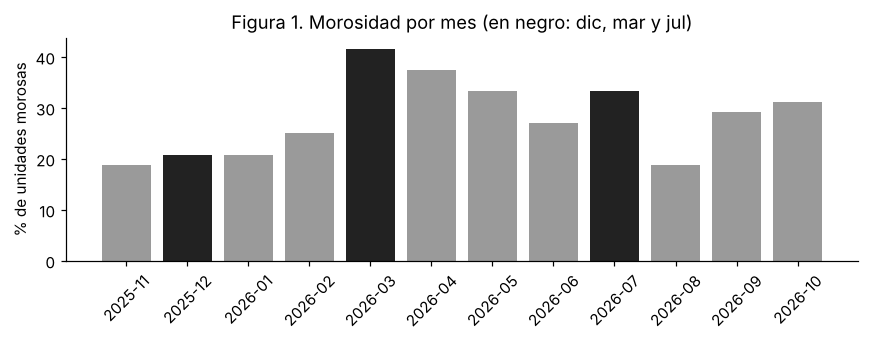

periodo
2025-11    18.8
2025-12    20.8
2026-01    20.8
2026-02    25.0
2026-03    41.7
2026-04    37.5
2026-05    33.3
2026-06    27.1
2026-07    33.3
2026-08    18.8
2026-09    29.2
2026-10    31.2


In [11]:
# Figura 1. Morosidad por mes (estacionalidad)
tasa_mes = ds.groupby("periodo").moroso.mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(tasa_mes.index, tasa_mes.values, color=GRIS)
for mes in ("2025-12", "2026-03", "2026-07"):
    ax.bar(mes, tasa_mes[mes], color=NEGRO)
ax.set_ylabel("% de unidades morosas"); ax.set_title("Figura 1. Morosidad por mes (en negro: dic, mar y jul)")
plt.xticks(rotation=45); plt.tight_layout(); plt.savefig("figuras/fig1_morosidad_por_mes.png"); plt.show()
print(tasa_mes.round(1).to_string())

**Conclusión.** La morosidad no es igual todos los meses: sube a 41.7 % en marzo (campaña escolar) y se arrastra a abril (37.5 %), y baja a 18.8 % en agosto, después de que varios se pusieron al día con la gratificación de julio. Esto confirma una relación esperada por el negocio y justifica dos cosas: incluir las variables `es_campana_escolar` y `es_mes_gratificacion`, y partir los datos por tiempo (no al azar).

## 5. Variables del modelo, limpieza y partición sin fuga
El modelo se usa **el día 1 de cada mes**, antes del vencimiento. Por eso no puede ver nada del mes que predice (`monto_pagado`, `fecha_pago`, `dias_retraso` y `pago_a_tiempo` de ese mes serían **fuga de información**: describen el resultado).

Para cada unidad y mes se recalcula el estado de cuenta **solo con los abonos anteriores al día 1** (igual que lo vería el MVP ese día) y se arman las variables con `calcular_variables()`. El primer mes (nov-2025) no tiene historial, así que se predice desde diciembre: 48 × 11 = 528 filas.

| Variable | Qué mide | Por qué sirve para la junta |
|---|---|---|
| meses_deuda_previos | meses seguidos sin cubrir (campo del contrato, recalculado al día 1) | quien ya debe suele seguir debiendo |
| moroso_mes_anterior | si el mes pasado fue moroso | **derivada**: hábito reciente |
| tasa_morosidad_hist | % de meses morosos en su historial | **derivada**: comportamiento de largo plazo |
| retraso_prom_3m | días de retraso promedio de los últimos 3 meses (sin pagar = 30) | **derivada**: detecta a los tardíos antes de que caigan |
| pagos_puntuales_3m | meses pagados hasta el día 10 en los últimos 3 | **derivada**: señal de buen pagador |
| es_mes_gratificacion | julio o diciembre | **derivada**: hay más liquidez |
| es_campana_escolar | marzo | **derivada**: hay menos liquidez |
| meses_historial | meses con información | el modelo sabe cuánta historia tiene |
| torre | A o B (categórica, one-hot) | posible diferencia entre torres |

In [12]:
# 5.1 Tabla de modelado: variables al día 1 de cada mes + objetivo del contrato de datos
filas = []
for u in UNIDADES:
    pagos_u = [(r.fecha, r.monto) for r in abonos[abonos.unidad == u].itertuples()]
    for i, t in enumerate(PERIODOS[1:], start=1):
        y, m = map(int, t.split("-"))
        corte = date(y, m, 1)
        historial, _ = aplicar_pagos_fifo([p for p in pagos_u if p[0] < corte], PERIODOS[:i])
        filas.append({"unidad": u, "periodo": t, **calcular_variables(historial, t, u)})

tabla = pd.DataFrame(filas).merge(ds[["unidad", "periodo", "moroso", "origen"]], on=["unidad", "periodo"])
tabla.to_csv("tabla_modelado_apf3.csv", index=False)
print(tabla.shape)
tabla.head()

(528, 14)


,unidad,periodo,meses_historial,meses_deuda_previos,deuda_soles,moroso_mes_anterior,tasa_morosidad_hist,retraso_prom_3m,pagos_puntuales_3m,es_mes_gratificacion,es_campana_escolar,torre,moroso,origen
0,A-101,2025-12,1,0,0.0,0,0.0000,0.00,1,1,0,A,1,simulado
1,A-101,2026-01,2,1,280.0,1,0.5000,15.00,1,0,0,A,0,simulado
2,A-101,2026-02,3,0,0.0,0,0.3333,13.67,1,0,0,A,0,simulado
3,A-101,2026-03,4,0,0.0,0,0.2500,13.67,1,0,1,A,1,simulado
4,A-101,2026-04,5,1,280.0,1,0.4000,13.67,1,0,0,A,1,simulado


In [13]:
# 5.2 Limpieza: nulos, duplicados y valores atípicos
print("Nulos por columna:", int(tabla.isna().sum().sum()))
print("Duplicados unidad-periodo:", int(tabla.duplicated(["unidad", "periodo"]).sum()))
# Criterio de negocio para atípicos: más de 3 cuotas de deuda o más de 90 días de retraso
print("Filas con deuda mayor a 3 cuotas (S/ 840):", int((tabla.deuda_soles > 3 * CUOTA).sum()))
print("Meses pagados con más de 90 días de retraso:", int((ds.dias_retraso > 90).sum()))
print("No se eliminan: son unidades que de verdad arrastran deuda y son justo los casos que interesa detectar.")
print("Tratamiento: en retraso_prom_3m el retraso se topa en 30 días, así un caso extremo no domina el promedio.")
print("El escalado (StandardScaler) se aplica dentro del Pipeline para que KNN y la regresión logística no se distorsionen.")

Nulos por columna: 0
Duplicados unidad-periodo: 0
Filas con deuda mayor a 3 cuotas (S/ 840): 17
Meses pagados con más de 90 días de retraso: 26
No se eliminan: son unidades que de verdad arrastran deuda y son justo los casos que interesa detectar.
Tratamiento: en retraso_prom_3m el retraso se topa en 30 días, así un caso extremo no domina el promedio.
El escalado (StandardScaler) se aplica dentro del Pipeline para que KNN y la regresión logística no se distorsionen.


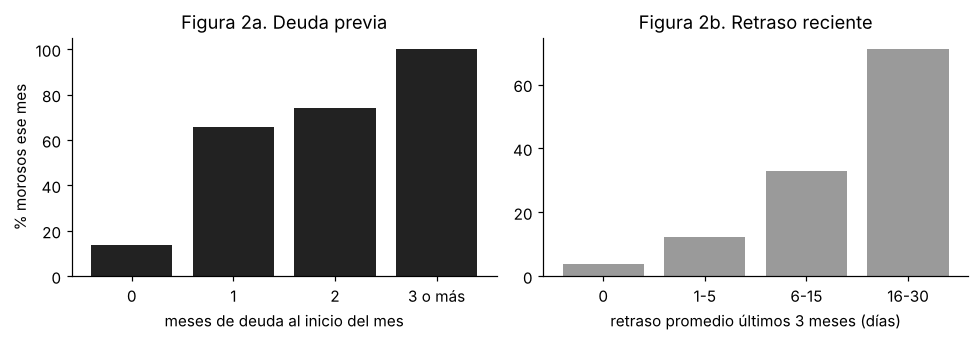

         % morosos  filas
deuda                    
0             13.6    398
1             65.7     70
2             74.1     27
3 o más      100.0     33
r
0         3.9
1-5      12.2
6-15     33.0
16-30    71.0


In [14]:
# Figura 2. Morosidad según los meses de deuda que ya arrastra la unidad
g = tabla.assign(deuda=tabla.meses_deuda_previos.clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3 o más"}))
t2 = g.groupby("deuda").moroso.agg(["mean", "count"])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].bar(t2.index, t2["mean"] * 100, color=NEGRO)
ax[0].set_xlabel("meses de deuda al inicio del mes"); ax[0].set_ylabel("% morosos ese mes")
ax[0].set_title("Figura 2a. Deuda previa")
r = tabla.assign(r=pd.cut(tabla.retraso_prom_3m, [-1, 0, 5, 15, 30], labels=["0", "1-5", "6-15", "16-30"]))
t3 = r.groupby("r", observed=True).moroso.mean() * 100
ax[1].bar(t3.index.astype(str), t3.values, color=GRIS)
ax[1].set_xlabel("retraso promedio últimos 3 meses (días)"); ax[1].set_title("Figura 2b. Retraso reciente")
plt.tight_layout(); plt.savefig("figuras/fig2_relaciones.png"); plt.show()
print(t2.assign(mean=(t2["mean"] * 100).round(1)).rename(columns={"mean": "% morosos", "count": "filas"}).to_string())
print(t3.round(1).to_string())

**Conclusión.** Dos relaciones esperadas por la junta se cumplen: (1) quien ya arrastra deuda sigue en mora (de 13.6 % sin deuda a 65.7 % con un mes y 100 % con tres o más), porque con la regla FIFO su nuevo pago cubre primero el mes viejo; y (2) quien viene pagando tarde tiende a caer en mora (3.9 % con 0 días de retraso promedio frente a 71.0 % con 16 a 30 días). Aun así, 13.6 % de las unidades **sin deuda** caen en mora: a esos la regla actual de "cobrar al que debe" nunca los ve, y ahí puede aportar el modelo.

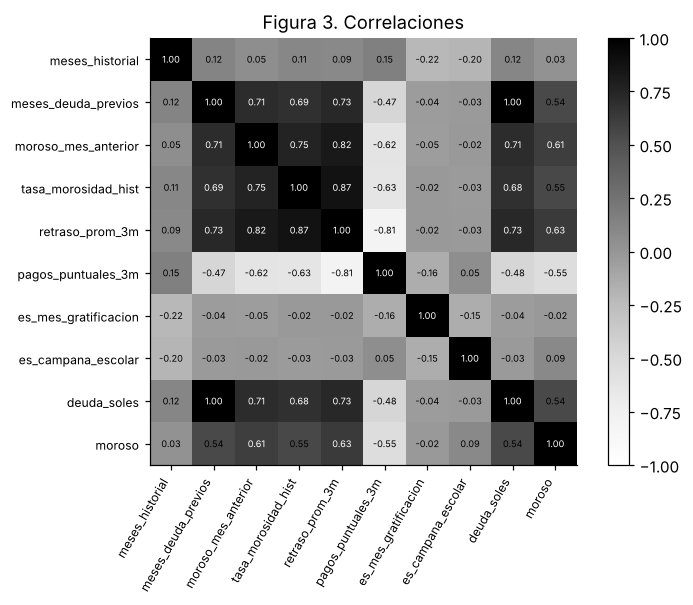

retraso_prom_3m         0.63
moroso_mes_anterior     0.61
tasa_morosidad_hist     0.55
meses_deuda_previos     0.54
deuda_soles             0.54
es_campana_escolar      0.09
meses_historial         0.03
es_mes_gratificacion   -0.02
pagos_puntuales_3m     -0.55


In [15]:
# Figura 3. Correlación entre variables numéricas y el objetivo
corr = tabla[VARIABLES_NUM + ["deuda_soles", "moroso"]].corr()
fig, ax = plt.subplots(figsize=(7, 5.6))
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6,
                color="white" if corr.iloc[i, j] > 0.6 else "black")
ax.set_title("Figura 3. Correlaciones"); plt.colorbar(im, fraction=0.04)
plt.tight_layout(); plt.savefig("figuras/fig3_correlaciones.png"); plt.show()
print(corr["moroso"].drop("moroso").sort_values(ascending=False).round(2).to_string())

**Conclusión.** Las variables más relacionadas con `moroso` son el retraso promedio de los últimos 3 meses (0.63), haber sido moroso el mes anterior (0.61) y los pagos puntuales recientes (−0.55). Ninguna pasa de 0.63, así que hay señal pero no una separación trivial. `deuda_soles` tiene correlación 1.00 con `meses_deuda_previos` (repite la misma información), por eso no entra al modelo.

In [16]:
# 5.3 Partición cronológica: se entrena con el pasado y se prueba con los últimos 3 meses
CORTE_TEST = "2026-07"
train = tabla[tabla.periodo <= CORTE_TEST].sort_values(["periodo", "unidad"]).reset_index(drop=True)
test = tabla[tabla.periodo > CORTE_TEST].sort_values(["periodo", "unidad"]).reset_index(drop=True)
X_train, y_train = train[VARIABLES], train.moroso
X_test, y_test = test[VARIABLES], test.moroso
print(f"Entrenamiento: {train.periodo.min()} a {train.periodo.max()} · {len(train)} filas · {y_train.sum()} morosos ({y_train.mean():.0%})")
print(f"Prueba:        {test.periodo.min()} a {test.periodo.max()} · {len(test)} filas · {y_test.sum()} morosos ({y_test.mean():.0%})")

# Validación cruzada también cronológica: entrena con los meses previos y valida con el siguiente
meses_val = ["2026-04", "2026-05", "2026-06", "2026-07"]
cv_crono = [(train.index[train.periodo < mv].to_numpy(), train.index[train.periodo == mv].to_numpy()) for mv in meses_val]
for (a, b), mv in zip(cv_crono, meses_val):
    print(f"  pliegue {mv}: entrena {len(a)} filas, valida {len(b)}")

Entrenamiento: 2025-12 a 2026-07 · 384 filas · 115 morosos (30%)
Prueba:        2026-08 a 2026-10 · 144 filas · 38 morosos (26%)
  pliegue 2026-04: entrena 192 filas, valida 48
  pliegue 2026-05: entrena 240 filas, valida 48
  pliegue 2026-06: entrena 288 filas, valida 48
  pliegue 2026-07: entrena 336 filas, valida 48


## 6. Línea base y modelos
- **Línea base 1 (trivial):** `DummyClassifier` que siempre dice "no moroso" (la clase mayoritaria).
- **Línea base 2 (lo que hace hoy la junta):** a fin de mes se revisa quién debe y se le cobra. Como regla: *recordar solo a quien ya debe algún mes*.
- **Modelos de la Unidad 3** (clasificación): regresión logística, KNN, árbol de decisión y Gradient Boosting.

El preprocesamiento va dentro de un `Pipeline` con `ColumnTransformer` (escalado de numéricas y one-hot de `torre`), así se ajusta **solo con los datos de entrenamiento** de cada pliegue.

Los hiperparámetros se eligen con `GridSearchCV` sobre la validación cronológica, usando **F2** como métrica (pesa más el recall, porque a la junta le cuesta más no avisar a un futuro moroso que mandar un recordatorio de más).

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone
from sklearn.metrics import (make_scorer, fbeta_score, f1_score, precision_score, recall_score,
                             accuracy_score, confusion_matrix)

f2 = make_scorer(fbeta_score, beta=2, zero_division=0)

def preprocesador():
    return ColumnTransformer([
        ("num", StandardScaler(), VARIABLES_NUM),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), VARIABLES_CAT),
    ])

candidatos = {
    "Regresión logística": (LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEMILLA),
                            {"modelo__C": [0.01, 0.1, 1, 10]}),
    "KNN": (KNeighborsClassifier(),
            {"modelo__n_neighbors": [5, 9, 15, 25], "modelo__weights": ["uniform", "distance"]}),
    "Árbol de decisión": (DecisionTreeClassifier(class_weight="balanced", random_state=SEMILLA),
                          {"modelo__max_depth": [2, 3, 4, 6], "modelo__min_samples_leaf": [5, 10, 20]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=SEMILLA),
                          {"modelo__n_estimators": [50, 100, 200], "modelo__max_depth": [1, 2, 3],
                           "modelo__learning_rate": [0.05, 0.1]}),
}

busquedas = {}
for nombre, (est, grilla) in candidatos.items():
    pipe = Pipeline([("pre", preprocesador()), ("modelo", est)])
    gs = GridSearchCV(pipe, grilla, scoring=f2, cv=cv_crono, n_jobs=1)
    gs.fit(X_train, y_train)
    busquedas[nombre] = gs
    print(f"{nombre:20s} F2 CV = {gs.best_score_:.3f} · {gs.best_params_}")

Regresión logística  F2 CV = 0.837 · {'modelo__C': 10}


KNN                  F2 CV = 0.783 · {'modelo__n_neighbors': 15, 'modelo__weights': 'uniform'}


Árbol de decisión    F2 CV = 0.774 · {'modelo__max_depth': 3, 'modelo__min_samples_leaf': 10}


Gradient Boosting    F2 CV = 0.697 · {'modelo__learning_rate': 0.05, 'modelo__max_depth': 2, 'modelo__n_estimators': 50}


In [18]:
# 6.1 Control de sobreajuste: entrenamiento vs validación cronológica (F1 con umbral 0.5)
def regla_junta(X):
    return (X["meses_deuda_previos"] >= 1).astype(int).to_numpy()

idx_val = np.concatenate([b for _, b in cv_crono])
filas_sob = []
for nombre, gs in busquedas.items():
    f1_tr = f1_score(y_train, gs.best_estimator_.predict(X_train))
    pred_val = np.empty(len(train)); pred_val[:] = np.nan
    for a, b in cv_crono:
        mod = clone(gs.best_estimator_).fit(X_train.iloc[a], y_train.iloc[a])
        pred_val[b] = mod.predict(X_train.iloc[b])
    f1_va = f1_score(y_train.iloc[idx_val], pred_val[idx_val])
    filas_sob.append([nombre, round(f1_tr, 3), round(f1_va, 3), round(f1_tr - f1_va, 3)])
sobreajuste = pd.DataFrame(filas_sob, columns=["modelo", "F1 entrenamiento", "F1 validación", "diferencia"])
sobreajuste

,modelo,F1 entrenamiento,F1 validación,diferencia
0,Regresión logística,0.723,0.783,-0.060
1,KNN,0.718,0.769,-0.051
2,Árbol de decisión,0.727,0.712,0.014
3,Gradient Boosting,0.707,0.693,0.014


**Conclusión.** No hay sobreajuste: el árbol y el boosting tienen apenas 0.014 de diferencia entre entrenamiento y validación, y en la regresión logística y KNN el F1 de entrenamiento es incluso menor, porque el entrenamiento incluye los primeros meses, que tienen poca historia y son más difíciles de predecir. Las medidas de control fueron: regularización C en la regresión logística, k = 15 vecinos en KNN, profundidad 3 y mínimo 10 casos por hoja en el árbol, y profundidad 2 con tasa de aprendizaje 0.05 en el boosting.

In [19]:
# 6.2 Selección del modelo con la validación cronológica (sin tocar el conjunto de prueba)
seleccion = pd.DataFrame({n: {"F2 validación": round(g.best_score_, 3)} for n, g in busquedas.items()}).T
seleccion["interpretable"] = ["sí (coeficientes)", "no", "sí (reglas)", "parcial (importancias)"]
seleccion = seleccion.sort_values("F2 validación", ascending=False)
mejor_nombre = seleccion.index[0]
print("Modelo seleccionado:", mejor_nombre)
seleccion

Modelo seleccionado: Regresión logística


,F2 validación,interpretable
Regresión logística,0.837,sí (coeficientes)
KNN,0.783,no
Árbol de decisión,0.774,sí (reglas)
Gradient Boosting,0.697,parcial (importancias)


**Conclusión.** Elegimos la regresión logística por dos razones: tiene el mejor F2 en la validación cronológica (0.837) y es la más fácil de explicar al tesorero, porque cada coeficiente dice si una variable sube o baja el riesgo. La elección se hizo sin mirar el conjunto de prueba.

In [20]:
# 6.3 Umbral de alerta: se elige con las probabilidades de validación (fuera del pliegue), no con la prueba
mejor = busquedas[mejor_nombre].best_estimator_
prob_val = np.full(len(train), np.nan)
for a, b in cv_crono:
    prob_val[b] = clone(mejor).fit(X_train.iloc[a], y_train.iloc[a]).predict_proba(X_train.iloc[b])[:, 1]
yv, pv = y_train.iloc[idx_val].to_numpy(), prob_val[idx_val]

umbrales = np.round(np.arange(0.20, 0.81, 0.05), 2)
curva = pd.DataFrame([[u, precision_score(yv, pv >= u, zero_division=0), recall_score(yv, pv >= u),
                       f1_score(yv, pv >= u), fbeta_score(yv, pv >= u, beta=2)] for u in umbrales],
                     columns=["umbral", "precision", "recall", "F1", "F2"]).round(3)
ok = curva[(curva.recall >= 0.80) & (curva.precision >= 0.60)]
UMBRAL = float(ok.sort_values(["F1", "umbral"], ascending=False).umbral.iloc[0]) if len(ok) else 0.5
print("Umbral elegido:", UMBRAL, "(el que cumple recall ≥ 0.80 y precisión ≥ 0.60 con mejor F1 en validación)")
curva

Umbral elegido: 0.6 (el que cumple recall ≥ 0.80 y precisión ≥ 0.60 con mejor F1 en validación)


,umbral,precision,recall,F1,F2
0,0.20,0.476,0.952,0.635,0.794
1,0.25,0.577,0.952,0.719,0.843
2,0.30,0.588,0.952,0.727,0.847
3,0.35,0.598,0.921,0.725,0.831
4,0.40,0.667,0.921,0.773,0.855
5,0.45,0.687,0.905,0.781,0.851
6,0.50,0.700,0.889,0.783,0.843
7,0.55,0.700,0.889,0.783,0.843
8,0.60,0.730,0.857,0.788,0.828
9,0.65,0.721,0.778,0.748,0.766


**Conclusión.** Con umbral 0.6, en validación el modelo detecta 85.7 % de los morosos y 73 % de sus alertas son correctas. Ese umbral queda fijo antes de usar el conjunto de prueba.

## 7. Evaluación en el conjunto de prueba (agosto a octubre 2026, se usa una sola vez)

In [21]:
def metricas(y, pred):
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "F1": f1_score(y, pred), "alertas": int(pred.sum())}

resultados = {}
dummy = Pipeline([("pre", preprocesador()), ("modelo", DummyClassifier(strategy="most_frequent"))]).fit(X_train, y_train)
resultados["Línea base 1: siempre 'al día'"] = metricas(y_test, dummy.predict(X_test))
resultados["Línea base 2: regla actual (ya debe)"] = metricas(y_test, regla_junta(X_test))
for nombre, gs in busquedas.items():
    resultados[f"{nombre} (umbral 0.5)"] = metricas(y_test, gs.best_estimator_.predict(X_test))
prob_test = mejor.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= UMBRAL).astype(int)
resultados[f"{mejor_nombre} · umbral {UMBRAL} (SELECCIONADO)"] = metricas(y_test, pred_test)

tabla_metricas = pd.DataFrame(resultados).T
tabla_metricas[["accuracy", "precision", "recall", "F1"]] = tabla_metricas[["accuracy", "precision", "recall", "F1"]].astype(float).round(3)
tabla_metricas.to_csv("tabla_metricas_test.csv")
print(f"En prueba hay {int(y_test.sum())} casos morosos reales de {len(y_test)} filas.")
tabla_metricas

En prueba hay 38 casos morosos reales de 144 filas.


,accuracy,precision,recall,F1,alertas
Línea base 1: siempre 'al día',0.736,0.000,0.000,0.000,0.0
Línea base 2: regla actual (ya debe),0.861,0.750,0.711,0.730,36.0
Regresión logística (umbral 0.5),0.868,0.702,0.868,0.776,47.0
KNN (umbral 0.5),0.854,0.743,0.684,0.712,35.0
Árbol de decisión (umbral 0.5),0.868,0.702,0.868,0.776,47.0
Gradient Boosting (umbral 0.5),0.875,0.778,0.737,0.757,36.0
Regresión logística · umbral 0.6 (SELECCIONADO),0.868,0.702,0.868,0.776,47.0


**Conclusión.** En la prueba (agosto a octubre, 38 morosos reales), el modelo elegido detecta 33 de los 38 (recall 0.868) y 70 % de sus alertas son correctas (precisión 0.702). La regla actual detecta 27 (recall 0.711) y la línea base trivial no detecta ninguno, aunque tenga 73.6 % de accuracy. Se cumple la meta del Paso 1 (recall ≥ 0.80 y precisión ≥ 0.60). El costo es avisar a 11 unidades más en tres meses (47 alertas frente a 36). El árbol de decisión sale con las mismas cifras en la prueba, pero ya lo habíamos descartado en la validación. Como los datos son simulados, estos resultados son indicativos y deben validarse con datos reales.

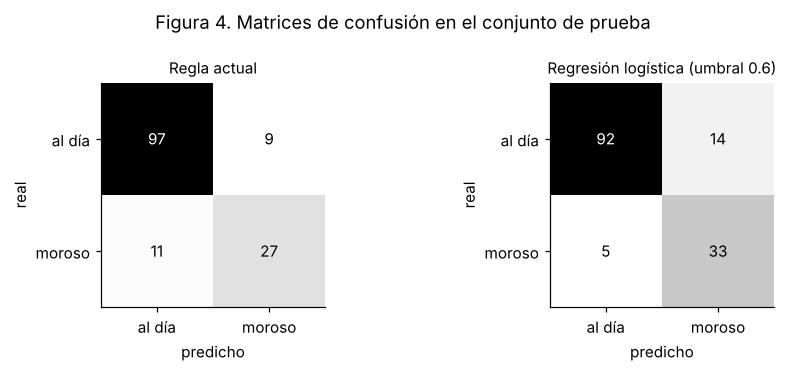

Verdaderos positivos 33 · falsos positivos 14 · falsos negativos 5 · verdaderos negativos 92


In [22]:
# Figura 4. Matriz de confusión del modelo seleccionado vs la regla actual
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.4))
for a, (titulo, pred) in zip(ax, [("Regla actual", regla_junta(X_test)), (f"{mejor_nombre} (umbral {UMBRAL})", pred_test)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["al día", "moroso"]).plot(ax=a, cmap="Greys", colorbar=False)
    a.set_title(titulo, fontsize=10); a.set_xlabel("predicho"); a.set_ylabel("real")
fig.suptitle("Figura 4. Matrices de confusión en el conjunto de prueba")
plt.tight_layout(); plt.savefig("figuras/fig4_matriz_confusion.png"); plt.show()
tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
print(f"Verdaderos positivos {tp} · falsos positivos {fp} · falsos negativos {fn} · verdaderos negativos {tn}")

In [23]:
# 7.1 Análisis de errores: casos donde el modelo falla
cols = ["unidad", "periodo", "meses_deuda_previos", "moroso_mes_anterior", "tasa_morosidad_hist",
        "retraso_prom_3m", "pagos_puntuales_3m", "es_mes_gratificacion"]
errores = test.assign(prob=prob_test.round(3), pred=pred_test)
fn_casos = errores[(errores.moroso == 1) & (errores.pred == 0)].sort_values("prob")
fp_casos = errores[(errores.moroso == 0) & (errores.pred == 1)].sort_values("prob", ascending=False)
print("FALSOS NEGATIVOS (fue moroso y el modelo no avisó):")
print(fn_casos[cols + ["prob"]].head(4).to_string(index=False))
print()
print("FALSOS POSITIVOS (el modelo avisó y la unidad pagó bien):")
print(fp_casos[cols + ["prob"]].head(4).to_string(index=False))

FALSOS NEGATIVOS (fue moroso y el modelo no avisó):
unidad periodo  meses_deuda_previos  moroso_mes_anterior  tasa_morosidad_hist  retraso_prom_3m  pagos_puntuales_3m  es_mes_gratificacion  prob
 B-104 2026-09                    0                    0                  0.0             0.00                   3                     0 0.101
 B-401 2026-09                    0                    0                  0.5             9.00                   1                     0 0.404
 A-602 2026-09                    0                    0                  0.5             6.00                   1                     0 0.435
 A-401 2026-10                    0                    0                  0.0             6.67                   1                     0 0.443

FALSOS POSITIVOS (el modelo avisó y la unidad pagó bien):
unidad periodo  meses_deuda_previos  moroso_mes_anterior  tasa_morosidad_hist  retraso_prom_3m  pagos_puntuales_3m  es_mes_gratificacion  prob
 B-504 2026-10                 

In [24]:
# Qué pasó realmente en esos casos (estado del contrato de datos de ese mes)
casos = pd.concat([fn_casos.head(3), fp_casos.head(3)])[["unidad", "periodo"]]
casos.merge(ds, on=["unidad", "periodo"])[["unidad", "periodo", "monto_pagado", "fecha_pago", "dias_retraso", "moroso"]]

,unidad,periodo,monto_pagado,fecha_pago,dias_retraso,moroso
0,B-104,2026-09,280.0,2026-10-02,22,1
1,B-401,2026-09,280.0,2026-10-16,36,1
2,A-602,2026-09,280.0,2026-10-13,33,1
3,B-504,2026-10,280.0,2026-10-18,8,0
4,B-302,2026-10,280.0,2026-10-14,4,0
5,A-503,2026-08,280.0,2026-08-24,14,0


**Hipótesis de los errores**
1. **B-104 en setiembre (falso negativo):** tenía 3 meses seguidos de pago puntual y de pronto pagó 22 días tarde. Probablemente cambió su situación (pérdida de ingresos, viaje), algo que el historial de pagos no muestra.
2. **B-401 y A-602 en setiembre (falsos negativos):** tienen historial mixto (la mitad de sus meses en mora), pero llegaron al 1 de setiembre sin deuda. Su probabilidad fue 0.40–0.44, debajo del umbral 0.6. Con un umbral más bajo se detectarían, a cambio de más alertas.
3. **B-504 y B-302 en octubre (falsos positivos):** debían 1 o 2 meses y aun así se pusieron al día dentro de los 15 días. Regularizar la deuda es una decisión que no se ve en los datos. Para la junta el costo es bajo: un recordatorio a alguien que sí debía.
4. **A-503 en agosto (falso positivo):** pagó con 14 días de retraso, justo debajo del límite de 15. Es un caso de frontera.

## 8. Interpretación de negocio

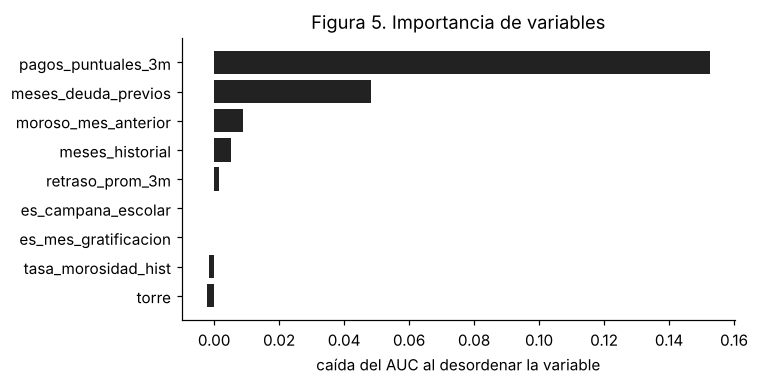

pagos_puntuales_3m      0.152
meses_deuda_previos     0.048
moroso_mes_anterior     0.009
meses_historial         0.005
retraso_prom_3m         0.002
es_campana_escolar      0.000
es_mes_gratificacion    0.000
tasa_morosidad_hist    -0.001
torre                  -0.002


In [25]:
# 8.1 Importancia de variables (permutation importance sobre la prueba, métrica AUC:
# cuánto empeora el modelo para ordenar a las unidades por riesgo si se desordena esa variable)
from sklearn.inspection import permutation_importance
imp = permutation_importance(mejor, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEMILLA)
importancia = pd.Series(imp.importances_mean, index=VARIABLES).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(importancia.index, importancia.values, color=NEGRO)
ax.set_xlabel("caída del AUC al desordenar la variable"); ax.set_title("Figura 5. Importancia de variables")
plt.tight_layout(); plt.savefig("figuras/fig5_importancia.png"); plt.show()
print(importancia.sort_values(ascending=False).round(3).to_string())

In [26]:
# 8.2 Coeficientes (si el modelo es la regresión logística): signo = sube o baja el riesgo
if mejor_nombre == "Regresión logística":
    nombres = mejor.named_steps["pre"].get_feature_names_out()
    coef = pd.Series(mejor.named_steps["modelo"].coef_[0], index=nombres).sort_values()
    print((coef.round(3)).to_string())

num__pagos_puntuales_3m     -1.149
num__retraso_prom_3m        -0.119
cat__torre_B                -0.091
num__es_mes_gratificacion   -0.049
num__tasa_morosidad_hist     0.032
num__meses_historial         0.202
num__moroso_mes_anterior     0.505
num__es_campana_escolar      0.542
num__meses_deuda_previos     0.793


In [27]:
# 8.3 Impacto estimado por mes en el periodo de prueba
mes_a_mes = []
for per, g in errores.groupby("periodo"):
    regla = regla_junta(g[VARIABLES])
    mes_a_mes.append({
        "periodo": per, "morosos reales": int(g.moroso.sum()),
        "alertas modelo": int(g.pred.sum()), "detectados modelo": int(((g.pred == 1) & (g.moroso == 1)).sum()),
        "alertas regla": int(regla.sum()), "detectados regla": int(((regla == 1) & (g.moroso == 1)).sum()),
    })
impacto = pd.DataFrame(mes_a_mes)
impacto.loc["promedio"] = impacto.mean(numeric_only=True).round(1)
impacto.loc["promedio", "periodo"] = "promedio"
nuevos = int(((errores.pred == 1) & (errores.moroso == 1) & (errores.meses_deuda_previos == 0)).sum())
print(f"Morosos detectados que todavía NO debían nada (la regla actual nunca los ve): {nuevos}")
print(f"Cuotas en riesgo avisadas a tiempo en 3 meses: {int(tp)} x S/ {CUOTA:.0f} = S/ {tp * CUOTA:,.0f}")
impacto

Morosos detectados que todavía NO debían nada (la regla actual nunca los ve): 6
Cuotas en riesgo avisadas a tiempo en 3 meses: 33 x S/ 280 = S/ 9,240


,periodo,morosos reales,alertas modelo,detectados modelo,alertas regla,detectados regla
0,2026-08,9.0,17.0,9.0,14.0,8.0
1,2026-09,14.0,14.0,11.0,8.0,8.0
2,2026-10,15.0,16.0,13.0,14.0,11.0
promedio,promedio,12.7,15.7,11.0,12.0,9.0


**Interpretación para la junta**
- **Qué sube el riesgo:** los meses de deuda que ya arrastra la unidad, haber sido moroso el mes anterior y que el mes sea marzo (campaña escolar). **Qué lo baja:** haber pagado puntual en los últimos 3 meses, que es la variable más importante. Los coeficientes de `retraso_prom_3m` y `tasa_morosidad_hist` son pequeños porque repiten información de `pagos_puntuales_3m` (correlación −0.81), así que no se interpretan solos.
- **Acciones que habilita:**
  1. El día 1 de cada mes, el MVP lista las unidades con alerta (unas 16 de 48) para recordarles antes del día 10.
  2. En febrero se manda un aviso general por la campaña escolar.
  3. A quien deja de pagar puntual aunque sea un mes, se le escribe temprano, porque es la señal más fuerte.
  4. A quien debe 2 meses o más se le propone un acuerdo de pago, porque un recordatorio no basta (100 % de los que deben 3 meses siguieron en mora).
- **Impacto estimado:** en los 3 meses de prueba, el modelo identificó a tiempo 33 de 38 cuotas en riesgo (S/ 9,240), 6 más que la regla actual, y 6 de ellas eran de unidades que todavía no debían nada. No es dinero recuperado: es dinero que la junta sabe a tiempo que está en riesgo. *Supuesto a validar en un piloto:* si 1 de cada 3 alertados paga a tiempo gracias al recordatorio, serían unas 3 a 4 cuotas más al mes cobradas a tiempo (≈ S/ 1,000).
- **Qué puede y qué no puede hacer el modelo:** ordena a las unidades según su riesgo usando solo su historial de pagos. No sabe por qué alguien deja de pagar, no decide sanciones y, como se entrenó con datos simulados, sus resultados se tienen que volver a medir con datos reales.

## 9. Exportación del modelo e integración con el MVP

In [28]:
# 9.1 Se guarda el Pipeline completo (preprocesamiento + modelo) y el umbral
artefacto = {
    "modelo": mejor,
    "umbral": UMBRAL,
    "variables": VARIABLES,
    "version": "morosidad-v1",
    "modelo_nombre": mejor_nombre,
    "entrenado_con": f"{train.periodo.min()} a {train.periodo.max()} (datos simulados)",
    "metricas_test": {k: float(v) for k, v in tabla_metricas.iloc[-1][["precision", "recall", "F1"]].items()},
    "sklearn": sklearn.__version__,
}
joblib.dump(artefacto, "modelo_morosidad.joblib")
print("Guardado: modelo_morosidad.joblib")

Guardado: modelo_morosidad.joblib


In [29]:
# 9.2 Registro nuevo con el esquema del MVP: la unidad pide su predicción para noviembre 2026.
# El historial es lo que el MVP ya tiene en su estado de cuenta (todos los meses hasta octubre).
def registro_mvp(unidad, periodo_objetivo="2026-11"):
    h = ds[ds.unidad == unidad]
    return {
        "unidad": unidad,
        "periodo_objetivo": periodo_objetivo,
        "historial": [{"periodo": r.periodo, "cuota": float(r.cuota), "monto_pagado": float(r.monto_pagado),
                       "dias_retraso": None if pd.isna(r.dias_retraso) else int(r.dias_retraso)}
                      for r in h.itertuples()],
    }

cargado = joblib.load("modelo_morosidad.joblib")
ejemplo = registro_mvp("B-304")
json.dump(ejemplo, open("ejemplo_entrada.json", "w"), indent=2)
salida = predecir(ejemplo, cargado)
json.dump(salida, open("ejemplo_salida.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps(salida, indent=2, ensure_ascii=False))

{
  "unidad": "B-304",
  "periodo_objetivo": "2026-11",
  "probabilidad_morosidad": 0.981,
  "umbral": 0.6,
  "riesgo": "alto",
  "alerta": true,
  "accion": "Enviar recordatorio antes del día 10",
  "version_modelo": "morosidad-v1"
}


In [30]:
# 9.3 Lo que mostraría el MVP el 1 de noviembre: lista de unidades a recordar, ordenada por riesgo
lista = pd.DataFrame([predecir(registro_mvp(u), cargado) for u in UNIDADES])
lista = lista.sort_values("probabilidad_morosidad", ascending=False)
lista.to_csv("alertas_2026-11.csv", index=False)
print("Unidades con alerta para noviembre 2026:", int(lista.alerta.sum()), "de", len(lista))
lista[["unidad", "probabilidad_morosidad", "riesgo", "accion"]].head(12)

Unidades con alerta para noviembre 2026: 18 de 48


,unidad,probabilidad_morosidad,riesgo,accion
15,A-404,0.996,alto,Enviar recordatorio antes del día 10
25,B-102,0.991,alto,Enviar recordatorio antes del día 10
8,A-301,0.982,alto,Enviar recordatorio antes del día 10
35,B-304,0.981,alto,Enviar recordatorio antes del día 10
23,A-604,0.962,alto,Enviar recordatorio antes del día 10
26,B-103,0.958,alto,Enviar recordatorio antes del día 10
2,A-103,0.932,alto,Enviar recordatorio antes del día 10
16,A-501,0.929,alto,Enviar recordatorio antes del día 10
21,A-602,0.928,alto,Enviar recordatorio antes del día 10
32,B-301,0.924,alto,Enviar recordatorio antes del día 10


In [31]:
# 9.4 Comprobación: la función de integración da lo mismo que el modelo dentro del notebook
fila_nb = tabla[(tabla.unidad == "B-304") & (tabla.periodo == "2026-10")]
reg = {"unidad": "B-304", "periodo_objetivo": "2026-10"}
# historial como lo veía el MVP el 1 de octubre (sin los abonos de octubre)
pagos_u = [(r.fecha, r.monto) for r in abonos[abonos.unidad == "B-304"].itertuples() if r.fecha < date(2026, 10, 1)]
reg["historial"], _ = aplicar_pagos_fifo(pagos_u, PERIODOS[:-1])
p_api = predecir(reg, cargado)["probabilidad_morosidad"]
p_nb = round(float(mejor.predict_proba(fila_nb[VARIABLES])[0, 1]), 3)
print("Notebook:", p_nb, "| función de integración:", p_api)
assert abs(p_api - p_nb) < 1e-6

Notebook: 0.957 | función de integración: 0.957


In [32]:
# 9.5 Parámetros para la web: la pantalla "Alertas ML" del MVP calcula la misma fórmula en TypeScript
# cuando la API de Python no está encendida. Se exportan medias, escalas, coeficientes y umbral.
assert mejor_nombre == "Regresión logística", "La web solo replica la regresión logística"
pre, lr = mejor.named_steps["pre"], mejor.named_steps["modelo"]
escalador = pre.named_transformers_["num"]
parametros_web = {
    "version": artefacto["version"],
    "modelo": mejor_nombre,
    "umbral": UMBRAL,
    "variables_num": VARIABLES_NUM,
    "media": escalador.mean_.tolist(),
    "escala": escalador.scale_.tolist(),
    "columnas": pre.get_feature_names_out().tolist(),
    "coeficientes": lr.coef_[0].tolist(),
    "intercepto": float(lr.intercept_[0]),
}
json.dump(parametros_web, open("model_params.json", "w"), indent=2, ensure_ascii=False)

# Casos de prueba para comprobar que la web da la misma probabilidad que Python
casos = []
for u in UNIDADES:
    r = registro_mvp(u)
    x = pd.DataFrame([calcular_variables(r["historial"], r["periodo_objetivo"], u)])[VARIABLES]
    casos.append({**r, "probabilidad": float(mejor.predict_proba(x)[0, 1])})
json.dump(casos, open("casos_paridad.json", "w"), indent=1)
print("Guardados: model_params.json y casos_paridad.json (48 casos)")
print(pd.Series(parametros_web["coeficientes"], index=parametros_web["columnas"]).round(3).to_string())

Guardados: model_params.json y casos_paridad.json (48 casos)
num__meses_historial         0.202
num__meses_deuda_previos     0.793
num__moroso_mes_anterior     0.505
num__tasa_morosidad_hist     0.032
num__retraso_prom_3m        -0.119
num__pagos_puntuales_3m     -1.149
num__es_mes_gratificacion   -0.049
num__es_campana_escolar      0.542
cat__torre_B                -0.091


**Contrato de integración**
- **Entrada** (`ejemplo_entrada.json`): `unidad`, `periodo_objetivo` e `historial` con `periodo`, `cuota`, `monto_pagado` y `dias_retraso` de cada mes. Son campos que el MVP ya calcula en su estado de cuenta.
- **Salida** (`ejemplo_salida.json`): `probabilidad_morosidad`, `umbral`, `riesgo` (bajo, medio o alto), `alerta` y `accion`.
- **Llamada:** la pantalla **Alertas ML (US12)** del MVP arma el historial de cada unidad con los pagos registrados antes del día 1 del mes y lo envía al microservicio `api_ml.py` (FastAPI) en `POST /api/v1/predecir-lote`.
- **Respaldo:** si la API no responde, la pantalla calcula la misma fórmula con `model_params.json`. `casos_paridad.json` sirve para comprobar que ambas dan la misma probabilidad (prueba automática del MVP).
- **Acción:** si `alerta = true`, la unidad aparece con su nivel de riesgo y un botón para enviarle un recordatorio cordial por WhatsApp (US13).
- **Pendiente para el PROY:** publicar la API en un servidor y protegerla junto con la pantalla (US15).

In [33]:
print("Archivos generados:")
for f in sorted(Path(".").glob("*")):
    if f.suffix in {".csv", ".json", ".joblib", ".py"} and f.name != "api_ml.py":
        print(" -", f.name)
for f in sorted(Path("figuras").glob("*.png")):
    print(" -", f)

Archivos generados:
 - alertas_2026-11.csv
 - casos_paridad.json
 - dataset_morosidad_apf3.csv
 - ejemplo_entrada.json
 - ejemplo_salida.json
 - model_params.json
 - modelo_morosidad.joblib
 - morosidad_ml.py
 - tabla_metricas_test.csv
 - tabla_modelado_apf3.csv
 - figuras/fig1_morosidad_por_mes.png
 - figuras/fig2_relaciones.png
 - figuras/fig3_correlaciones.png
 - figuras/fig4_matriz_confusion.png
 - figuras/fig5_importancia.png
